# Fetal Ultrasound Plane Classification: Model Training

This notebook trains and evaluates the plane classifier on the images produced by the Phase 2 pipeline. A ResNet18 is first trained on the Spanish dataset (sections 1–7) and then fine-tuned on the African development images (sections 8–9). A leave-one-site-out evaluation measures performance on countries the model has not seen (sections 10–11), and the final model is scored once on the held-out African test set (sections 12–13).

## 0. Setup

Libraries, folder paths and fixed values. The training code is in `src/training.py`, and the augmentation and scaling steps come from `src/transformers.py`.

In [2]:
import inspect
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

from src.training import build_model, fine_tune, fit, get_device, load_model, make_loader, predict

random_seed = 42
np.random.seed(random_seed)
torch.manual_seed(random_seed)

PLANES = ["Fetal abdomen", "Fetal brain", "Fetal femur", "Fetal thorax"]
SHORT_NAMES = [plane.replace("Fetal ", "") for plane in PLANES]
device = get_device()
print("Device:", device)

Device: mps


## 1. Loading the processed data

The cleaned tables and standardised images were saved at the end of Phase 2. Each row of the table matches the image at the same position in the image array. The Spanish data is already split by patient into training and validation partitions.

In [3]:
fetal_clean = pd.read_csv(PROCESSED / "fetal_clean.csv")
fetal_images = np.load(PROCESSED / "fetal_processed.npz")["images"]

african_clean = pd.read_csv(PROCESSED / "african_clean.csv")
african_images = np.load(PROCESSED / "african_processed.npz")["images"]

print("Spanish:", fetal_images.shape, "| African:", african_images.shape)

Spanish: (6059, 224, 224) | African: (396, 224, 224)


In [4]:
training = fetal_clean[fetal_clean["partition"] == "training"]
validation = fetal_clean[fetal_clean["partition"] == "validation"]

pd.crosstab(fetal_clean["Plane"], fetal_clean["partition"], margins=True)

partition,training,validation,All
Plane,,,
Fetal abdomen,590,101,691
Fetal brain,2548,415,2963
Fetal femur,875,131,1006
Fetal thorax,1207,192,1399
All,5220,839,6059


## 2. Class weights

Brain images make up about half of the Spanish training data. As in Phase 2, each class gets a weight in the loss function so that mistakes on rarer classes count more. The weights come from the training partition only.

In [5]:
weights = compute_class_weight("balanced", classes=np.arange(len(PLANES)), y=training["label"])
pd.Series(weights, index=PLANES).round(2)

Fetal abdomen    2.21
Fetal brain      0.51
Fetal femur      1.49
Fetal thorax     1.08
dtype: float64

## 3. Model and training settings

The model is a ResNet18 pretrained on ImageNet, the same network used for the embeddings in Phase 2. Its final layer is replaced with one that outputs the four planes, and the whole network is fine-tuned.

| Setting | Value | Reason |
|---|---|---|
| Optimiser | Adam, learning rate 0.0001 | A small learning rate adjusts the pretrained weights without erasing them |
| Weight decay | 0.0001 | Mild regularisation |
| Batch size | 32 | A standard batch size for fine-tuning |
| Epochs | up to 10 | Stops early if validation macro-F1 does not improve for 3 epochs |
| Loss | Cross-entropy with the class weights above | Handles the class imbalance |
| Augmentation | Training images only (Phase 2, section 12.2) | Makes brightness, contrast, blur and noise unreliable clues |

The best epoch is chosen by **macro-F1** on the validation set: the F1 score is calculated for each plane and then averaged, so each plane counts equally however many images it has.

In [6]:
print(inspect.getsource(fit))

def fit(model, train_loader, val_loader, loss_fn, optimizer, device, epochs=10, patience=3):
    """Trains for up to `epochs`, keeping the weights with the best validation macro-F1.

    Stops early if validation macro-F1 has not improved for `patience` epochs.
    Returns the training history (one row per epoch).
    """
    history, best_f1, best_weights, waited = [], -1.0, None, 0
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
        true, pred, _ = predict(model, val_loader, device)
        val_f1 = f1_score(true, pred, average="macro")
        val_accuracy = (true == pred).mean()
        history.append({"epoch": epoch, "train loss": train_loss,
                        "validation accuracy": val_accuracy, "validation macro-F1": val_f1})
        print(f"Epoch {epoch}: loss {train_loss:.3f} | validation accuracy {val_accuracy:.3f} | "
              f"macro-F1 {val_f1:.3f}")

        if val_f1 > best_f1:
  

In [7]:
train_loader = make_loader(fetal_images[training.index], training["label"], train=True, seed=random_seed)
val_loader = make_loader(fetal_images[validation.index], validation["label"])

model = build_model(num_classes=len(PLANES)).to(device)
loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32).to(device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

## 4. Training

Each epoch is one pass over the 5,220 training images, followed by an evaluation on the 839 validation images. The best weights are saved to `models/`, which is not committed to the repository.

In [7]:
history = fit(model, train_loader, val_loader, loss_fn, optimizer, device, epochs=10, patience=3)
torch.save(model.state_dict(), MODELS / "spanish_baseline.pt")
history = pd.DataFrame(history).set_index("epoch")
history.round(3)

Epoch 1: loss 0.204 | validation accuracy 0.983 | macro-F1 0.980
Epoch 2: loss 0.058 | validation accuracy 0.990 | macro-F1 0.989
Epoch 3: loss 0.032 | validation accuracy 0.992 | macro-F1 0.990
Epoch 4: loss 0.031 | validation accuracy 0.993 | macro-F1 0.992
Epoch 5: loss 0.032 | validation accuracy 0.992 | macro-F1 0.988
Epoch 6: loss 0.020 | validation accuracy 0.996 | macro-F1 0.996
Epoch 7: loss 0.020 | validation accuracy 0.992 | macro-F1 0.990
Epoch 8: loss 0.014 | validation accuracy 0.994 | macro-F1 0.993
Epoch 9: loss 0.015 | validation accuracy 0.992 | macro-F1 0.990
Stopped early: no improvement for 3 epochs.


,train loss,validation accuracy,validation macro-F1
epoch,,,
1,0.204,0.983,0.980
2,0.058,0.990,0.989
3,0.032,0.992,0.990
4,0.031,0.993,0.992
5,0.032,0.992,0.988
6,0.020,0.996,0.996
7,0.020,0.992,0.990
8,0.014,0.994,0.993
9,0.015,0.992,0.990


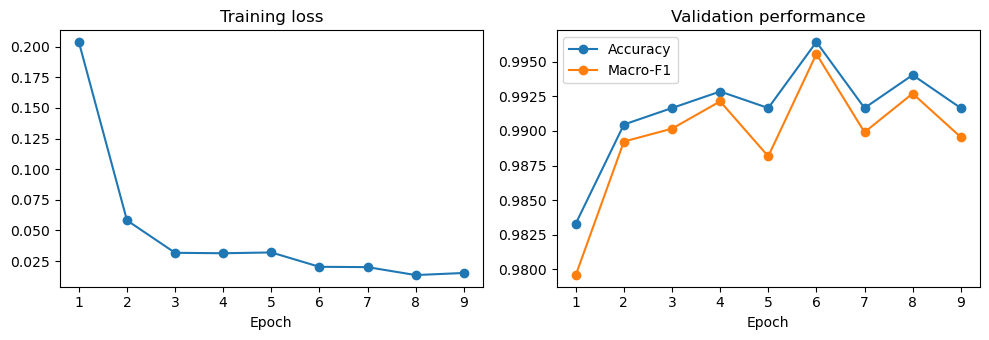

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history.index, history["train loss"], marker="o")
axes[0].set_title("Training loss")
axes[1].plot(history.index, history["validation accuracy"], marker="o", label="Accuracy")
axes[1].plot(history.index, history["validation macro-F1"], marker="o", label="Macro-F1")
axes[1].set_title("Validation performance")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Epoch")
plt.tight_layout()
plt.savefig(FIGURES / "fig6_1_training_history.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Optional: load the saved baseline instead of retraining it.
# model = load_model(MODELS / "spanish_baseline.pt", device)

## 5. Results on the Spanish validation set

To judge whether the scores are good, they are compared with a model that always predicts the most common plane (brain).

In [9]:
true, pred, _ = predict(model, val_loader, device)
majority = np.full_like(true, training["label"].mode()[0])

pd.DataFrame({
    "Accuracy": [(majority == true).mean(), (pred == true).mean()],
    "Macro-F1": [f1_score(true, majority, average="macro"), f1_score(true, pred, average="macro")],
}, index=["Always predict brain", "ResNet18 baseline"]).round(3)

,Accuracy,Macro-F1
Always predict brain,0.495,0.165
ResNet18 baseline,0.996,0.996


In [10]:
report = classification_report(true, pred, target_names=SHORT_NAMES, output_dict=True)
pd.DataFrame(report).T.round(3)

,precision,recall,f1-score,support
abdomen,0.990,1.000,0.995,101.000
brain,1.000,0.998,0.999,415.000
femur,0.992,1.000,0.996,131.000
thorax,0.995,0.990,0.992,192.000
accuracy,0.996,0.996,0.996,0.996
macro avg,0.994,0.997,0.996,839.000
weighted avg,0.996,0.996,0.996,839.000


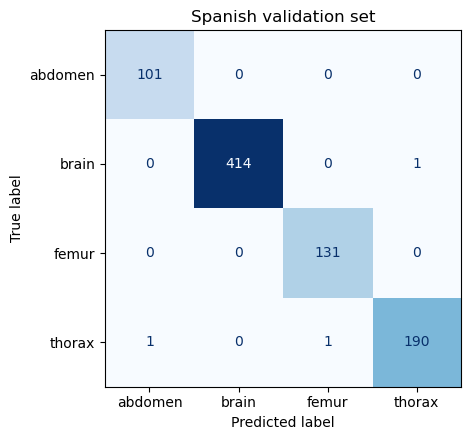

In [11]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(true, pred, display_labels=SHORT_NAMES, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Spanish validation set")
plt.tight_layout()
plt.savefig(FIGURES / "fig6_2_confusion_matrix_spanish.png", dpi=300, bbox_inches="tight")
plt.show()

### 5.1 Results by machine

If the model works equally well on every machine, the acquisition differences found in Phase 2 are not affecting it within the Spanish data.

In [12]:
results = validation.assign(correct=(pred == true))
results.groupby("US_Machine").agg(images=("correct", "size"), accuracy=("correct", "mean")).round(3)

,images,accuracy
US_Machine,,
Aloka,189,0.995
Other,14,1.000
Voluson E6,576,0.997
Voluson S10,60,1.000


## 6. Applying the Spanish model to the African images

The Spanish model has not seen any African images. Evaluating it on the African development images shows how much performance is lost when the model moves to new countries and equipment. This is the gap that fine-tuning on African images should close. The African test images are not used here; they are kept for the final evaluation.

In [13]:
development = african_clean[african_clean["partition"] == "development"]
african_loader = make_loader(african_images[development.index], development["label"])

true_af, pred_af, _ = predict(model, african_loader, device)
print(f"Accuracy {(pred_af == true_af).mean():.3f} | macro-F1 {f1_score(true_af, pred_af, average='macro'):.3f}")

Accuracy 0.953 | macro-F1 0.948


In [14]:
african_results = development.assign(correct=(pred_af == true_af))
african_results.groupby("Center").agg(images=("correct", "size"), accuracy=("correct", "mean")).round(3)

,images,accuracy
Center,,
Algeria,60,0.983
Egypt,77,0.948
Ghana,57,0.912
Malawi,67,0.955
Uganda,60,0.967


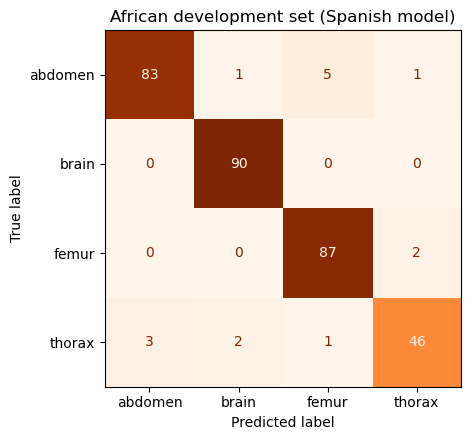

In [15]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(true_af, pred_af, labels=range(len(PLANES)), display_labels=SHORT_NAMES,
                                        cmap="Oranges", ax=ax, colorbar=False)
ax.set_title("African development set (Spanish model)")
plt.tight_layout()
plt.savefig(FIGURES / "fig6_3_confusion_matrix_african.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Baseline summary

| | Images | Accuracy | Macro-F1 |
|---|---|---|---|
| Always predict brain (Spanish validation) | 839 | 0.495 | 0.165 |
| ResNet18 baseline (Spanish validation) | 839 | 0.996 | 0.996 |
| ResNet18 baseline (African development, no African training) | 321 | 0.953 | 0.948 |

**Training.** The model learned the Spanish planes quickly: validation accuracy was already 98% after the first epoch. The best epoch was 6, and training stopped after epoch 9 because the next three epochs did not improve on it.

**Spanish validation set.** Only 3 of 839 images were misclassified (one brain image and two thorax images), and accuracy was between 99.5% and 100% on every machine. Within the Spanish data, the model is not affected by which machine took the image.

**African development set.** Without seeing any African images, the model still classified 95.3% of them correctly, a drop of about 4 percentage points from the Spanish validation set. This drop is smaller than expected, which suggests the Phase 2 preprocessing and augmentation already make the images from different sites fairly comparable. The remaining errors are concentrated in two places:

- **Thorax** was the weakest plane (46 of 52 correct), with errors spread across the other three planes. It is also the smallest African class and is missing in Ghana and Uganda.
- **Ghana** was the weakest country (91.2%), mainly through abdomen and femur errors. This matches Phase 2, where Ghana's images were the darkest.

Brain images were classified correctly in every country.

**Next step.** The next step fine-tunes this model on the African development images. Because only about 15 of the 321 images are wrong, the aim is to close the remaining gap on thorax and Ghana, and the results will be reported as an average across the five patient-grouped folds rather than as a single number. The African test images remain unused until the final evaluation.


## 8. Fine-tuning on the African images

After the Spanish baseline, I fine-tuned it on the African development images. Each African model starts from the Spanish weights, so it keeps what it learned from the 5,220 Spanish images and adjusts to the African ones.

With only 321 development images, a single train/validation split would give a noisy result, so I used **5-fold cross-validation grouped by patient**: the images are split into five folds, each fold is held out once while the model is fine-tuned on the other four, and no patient appears on both sides. Every development image is therefore scored once by a model that did not see it. The Spanish model's predictions from section 6 are scored on the same folds, so the two can be compared image by image.

| Setting | Value | Reason |
|---|---|---|
| Starting weights | Spanish baseline (section 4) | Builds on the Spanish training |
| Optimiser | Adam, learning rate 0.00005 | Half the Spanish rate, so the small dataset adjusts the weights gently |
| Batch size | 16 | About 16 updates per epoch from roughly 257 training images |
| Epochs | 5, fixed | No early stopping, because the held-out fold is only for scoring |
| Class weights | Recalculated from each fold's training images | Thorax is the smallest African class |
| Augmentation | Training images only | Same as the Spanish training |

The African test images are still not used.

### 8.1 Patient-grouped folds

In [16]:
dev_images = african_images[development.index]
dev_labels = development["label"].to_numpy()

folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=random_seed)
fold_of_image = np.zeros(len(development), dtype=int)
for fold, (_, held_out) in enumerate(folds.split(dev_images, dev_labels, development["patient_id"]), start=1):
    fold_of_image[held_out] = fold

development = development.assign(fold=fold_of_image)
pd.crosstab(development["fold"], development["Plane"], margins=True)

Plane,Fetal abdomen,Fetal brain,Fetal femur,Fetal thorax,All
fold,,,,,
1,17,18,17,10,62
2,19,19,19,11,68
3,18,18,18,13,67
4,17,16,16,9,58
5,19,19,19,9,66
All,90,90,89,52,321


### 8.2 Fine-tuning each fold

In [17]:
finetuned_pred = np.zeros(len(development), dtype=int)
fold_results = []

for fold in range(1, 6):
    train_rows = fold_of_image != fold
    held_out = fold_of_image == fold
    torch.manual_seed(random_seed + fold)

    fold_model = load_model(MODELS / "spanish_baseline.pt", device)
    fold_weights = compute_class_weight("balanced", classes=np.arange(len(PLANES)), y=dev_labels[train_rows])
    fold_loss = torch.nn.CrossEntropyLoss(weight=torch.tensor(fold_weights, dtype=torch.float32).to(device))
    fold_optimizer = torch.optim.Adam(fold_model.parameters(), lr=5e-5, weight_decay=1e-4)
    fold_loader = make_loader(dev_images[train_rows], dev_labels[train_rows], train=True, batch_size=16,
                              seed=random_seed + fold)

    losses = fine_tune(fold_model, fold_loader, fold_loss, fold_optimizer, device, epochs=5)
    true, pred, _ = predict(fold_model, make_loader(dev_images[held_out], dev_labels[held_out]), device)
    finetuned_pred[held_out] = pred

    fold_results.append({
        "fold": fold,
        "images": held_out.sum(),
        "Spanish model accuracy": (pred_af[held_out] == true).mean(),
        "Fine-tuned accuracy": (pred == true).mean(),
        "Spanish model macro-F1": f1_score(true, pred_af[held_out], average="macro", labels=range(len(PLANES))),
        "Fine-tuned macro-F1": f1_score(true, pred, average="macro", labels=range(len(PLANES))),
    })
    print(f"Fold {fold}: final training loss {losses[-1]:.3f} | accuracy {(pred == true).mean():.3f}")

Fold 1: final training loss 0.104 | accuracy 0.952
Fold 2: final training loss 0.072 | accuracy 0.985
Fold 3: final training loss 0.027 | accuracy 0.985
Fold 4: final training loss 0.045 | accuracy 0.966
Fold 5: final training loss 0.067 | accuracy 0.970


In [18]:
fold_results = pd.DataFrame(fold_results).set_index("fold")
summary = fold_results.drop(columns="images").agg(["mean", "std"])
pd.concat([fold_results, summary]).round(3)

,images,Spanish model accuracy,Fine-tuned accuracy,Spanish model macro-F1,Fine-tuned macro-F1
1,62.0,0.968,0.952,0.958,0.942
2,68.0,0.971,0.985,0.969,0.982
3,67.0,0.985,0.985,0.983,0.983
4,58.0,0.948,0.966,0.948,0.969
5,66.0,0.894,0.970,0.872,0.959
mean,NaN,0.953,0.971,0.946,0.967
std,NaN,0.036,0.014,0.043,0.017


### 8.3 Where fine-tuning helped

Every development image now has two predictions: one from the Spanish model and one from the fine-tuned model of the fold that held it out. Comparing them shows which planes and countries improved.

In [19]:
comparison = development.assign(
    spanish_correct=(pred_af == dev_labels),
    finetuned_correct=(finetuned_pred == dev_labels),
)
print("Fixed by fine-tuning:", (~comparison["spanish_correct"] & comparison["finetuned_correct"]).sum())
print("Broken by fine-tuning:", (comparison["spanish_correct"] & ~comparison["finetuned_correct"]).sum())

columns = {"spanish_correct": "Spanish model", "finetuned_correct": "Fine-tuned"}
by_plane = comparison.groupby("Plane")[list(columns)].mean().rename(columns=columns)
by_country = comparison.groupby("Center")[list(columns)].mean().rename(columns=columns)
pd.concat({"Accuracy by plane": by_plane, "Accuracy by country": by_country}).round(3)

Fixed by fine-tuning: 11
Broken by fine-tuning: 5


Spanish model  Fine-tuned
Accuracy by plane   Fetal abdomen          0.922       0.956
                    Fetal brain            1.000       1.000
                    Fetal femur            0.978       0.989
                    Fetal thorax           0.885       0.923
Accuracy by country Algeria                0.983       0.983
                    Egypt                  0.948       0.935
                    Ghana                  0.912       0.965
                    Malawi                 0.955       0.985
                    Uganda                 0.967       1.000

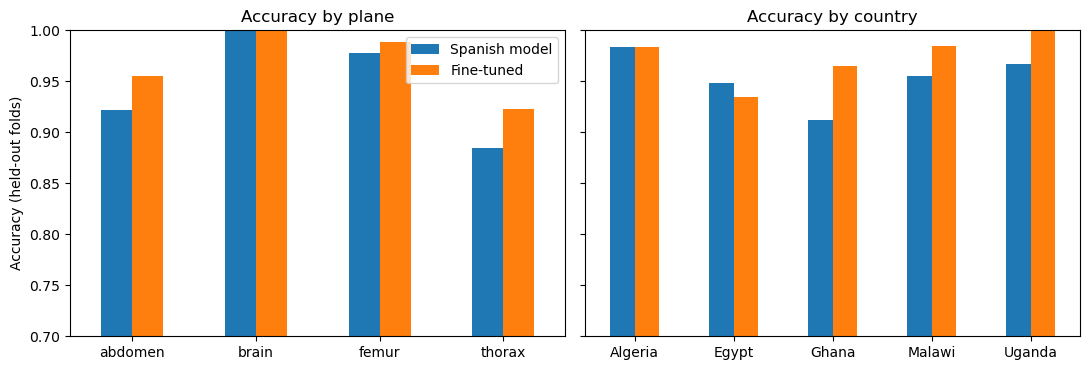

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
by_plane.rename(index=lambda name: name.replace("Fetal ", "")).plot.bar(ax=axes[0], rot=0)
by_country.plot.bar(ax=axes[1], rot=0, legend=False)
axes[0].set_title("Accuracy by plane")
axes[1].set_title("Accuracy by country")
axes[0].set_ylabel("Accuracy (held-out folds)")
axes[0].set_ylim(0.7, 1.0)
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIGURES / "fig6_4_finetuning_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

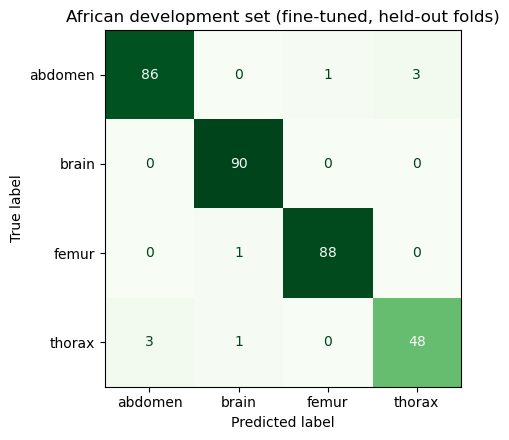

In [21]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(dev_labels, finetuned_pred, labels=range(len(PLANES)),
                                        display_labels=SHORT_NAMES, cmap="Greens", ax=ax, colorbar=False)
ax.set_title("African development set (fine-tuned, held-out folds)")
plt.tight_layout()
plt.savefig(FIGURES / "fig6_5_confusion_matrix_finetuned.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.4 Final African model

The cross-validation above measures how well fine-tuning works. For the final evaluation, one model is fine-tuned on all 321 development images with the same settings and saved. It will be scored on the African test images only once, in section 12.

In [22]:
torch.manual_seed(random_seed)
african_model = load_model(MODELS / "spanish_baseline.pt", device)
african_weights = compute_class_weight("balanced", classes=np.arange(len(PLANES)), y=dev_labels)
african_loss = torch.nn.CrossEntropyLoss(weight=torch.tensor(african_weights, dtype=torch.float32).to(device))
african_optimizer = torch.optim.Adam(african_model.parameters(), lr=5e-5, weight_decay=1e-4)
african_loader = make_loader(dev_images, dev_labels, train=True, batch_size=16, seed=random_seed)

fine_tune(african_model, african_loader, african_loss, african_optimizer, device, epochs=5)
torch.save(african_model.state_dict(), MODELS / "african_finetuned.pt")
print("Saved:", MODELS / "african_finetuned.pt")

Saved: /Users/mac/Downloads/AISD/Project/fetal-ultrasound-plane-classification/models/african_finetuned.pt


## 9. Fine-tuning summary

| | Accuracy (mean ± SD across folds) | Macro-F1 (mean ± SD across folds) | Correct images |
|---|---|---|---|
| Spanish model, no African training | 0.953 ± 0.036 | 0.946 ± 0.043 | 306 of 321 |
| Fine-tuned on African images | 0.971 ± 0.014 | 0.967 ± 0.017 | 312 of 321 |

**Overall.** Fine-tuning on the African development images raised accuracy from 95.3% to 97.1% and macro-F1 from 0.946 to 0.967. The results also became more consistent across folds: the standard deviation fell from about 0.04 to under 0.02, mainly because fold 5, the Spanish model's weakest fold, rose from 89.4% to 97.0%.

**The gain is small in absolute terms.** Fine-tuning fixed 11 images and broke 5, a net gain of 6 images. If fine-tuning made no real difference, a split at least this uneven would occur about one time in five, so this result alone does not prove that fine-tuning helps. The improvement is, however, in the expected direction for both target weaknesses identified in section 7.

**Where it helped.**

- **Thorax** improved from 88.5% to 92.3% (46 to 48 of 52) and **abdomen** from 92.2% to 95.6%.
- **Ghana**, the weakest country for the Spanish model, improved from 91.2% to 96.5%, and Uganda reached 100%. Section 10 shows that the Ghana gain depends on the model having seen other Ghana images during training.
- Algeria did not change, and Egypt fell by one image (94.8% to 93.5%). Fold 1 was also slightly worse after fine-tuning (96.8% to 95.2%).

**Remaining errors.** Of the 9 remaining errors, 6 are abdomen and thorax confused with each other. These two planes are neighbouring cross-sections of the fetal trunk and can look similar, so this is the hardest distinction for the model.

**Next steps.** The final model, fine-tuned on all 321 development images, is saved in `models/african_finetuned.pt`. Before it is scored on the test set, a leave-one-site-out evaluation will show how the model performs on a country it has never seen, which is the situation a deployed model would face at a new hospital.


## 10. Leave-one-site-out evaluation

In section 8, every held-out fold contained patients from all five countries, so the model had always seen other images from the same country. A model deployed at a new hospital would not have that advantage. To measure this, I held out one country at a time: the Spanish model was fine-tuned on the development images of the other four countries and scored on the held-out country.

Each country stands in for an acquisition site here: as found in Phase 2, its images differ mainly in equipment and screen layout, together with its patient population, and these cannot be separated with this data. Ghana and Uganda have no thorax images, so their results cover three planes.

The settings are the same as in section 8 (5 epochs, learning rate 0.00005, batch size 16, class weights from the training images). Each country can then be compared under three conditions:

| Condition | African training images | Seen this country? |
|---|---|---|
| Spanish model (section 6) | None | No |
| Leave-one-site-out (this section) | The other four countries | No |
| Fine-tuned, patient-grouped folds (section 8) | All five countries | Yes, other patients |

### 10.1 Fine-tuning without each country

In [23]:
countries = development["Center"].to_numpy()
site_pred = np.zeros(len(development), dtype=int)

for country in sorted(development["Center"].unique()):
    train_rows = countries != country
    held_out = countries == country
    torch.manual_seed(random_seed)

    site_model = load_model(MODELS / "spanish_baseline.pt", device)
    site_weights = compute_class_weight("balanced", classes=np.arange(len(PLANES)), y=dev_labels[train_rows])
    site_loss = torch.nn.CrossEntropyLoss(weight=torch.tensor(site_weights, dtype=torch.float32).to(device))
    site_optimizer = torch.optim.Adam(site_model.parameters(), lr=5e-5, weight_decay=1e-4)
    site_loader = make_loader(dev_images[train_rows], dev_labels[train_rows], train=True, batch_size=16,
                              seed=random_seed)

    fine_tune(site_model, site_loader, site_loss, site_optimizer, device, epochs=5)
    _, pred, _ = predict(site_model, make_loader(dev_images[held_out], dev_labels[held_out]), device)
    site_pred[held_out] = pred
    print(f"{country}: trained on {train_rows.sum()} images | accuracy on {held_out.sum()} held-out images "
          f"{(pred == dev_labels[held_out]).mean():.3f}")

Algeria: trained on 261 images | accuracy on 60 held-out images 0.950
Egypt: trained on 244 images | accuracy on 77 held-out images 0.974
Ghana: trained on 264 images | accuracy on 57 held-out images 0.807
Malawi: trained on 254 images | accuracy on 67 held-out images 1.000
Uganda: trained on 261 images | accuracy on 60 held-out images 0.983


### 10.2 Results by country

Macro-F1 is calculated over the planes each country actually has.

In [24]:
def site_scores(pred):
    rows = {}
    for country in sorted(development["Center"].unique()):
        held_out = countries == country
        true = dev_labels[held_out]
        rows[country] = {"accuracy": (pred[held_out] == true).mean(),
                         "macro-F1": f1_score(true, pred[held_out], average="macro", labels=np.unique(true))}
    rows["All countries"] = {"accuracy": (pred == dev_labels).mean(),
                             "macro-F1": f1_score(dev_labels, pred, average="macro")}
    return pd.DataFrame(rows).T


site_results = pd.concat({
    "Spanish model": site_scores(pred_af),
    "Leave-one-site-out": site_scores(site_pred),
    "Fine-tuned (all countries)": site_scores(finetuned_pred),
}, axis=1)
site_results.round(3)

Spanish model          Leave-one-site-out           \
                   accuracy macro-F1           accuracy macro-F1   
Algeria               0.983    0.983              0.950    0.949   
Egypt                 0.948    0.948              0.974    0.974   
Ghana                 0.912    0.929              0.807    0.892   
Malawi                0.955    0.955              1.000    1.000   
Uganda                0.967    0.974              0.983    0.991   
All countries         0.953    0.948              0.947    0.938   

              Fine-tuned (all countries)           
                                accuracy macro-F1  
Algeria                            0.983    0.983  
Egypt                              0.935    0.935  
Ghana                              0.965    0.965  
Malawi                             0.985    0.985  
Uganda                             1.000    1.000  
All countries                      0.972    0.968

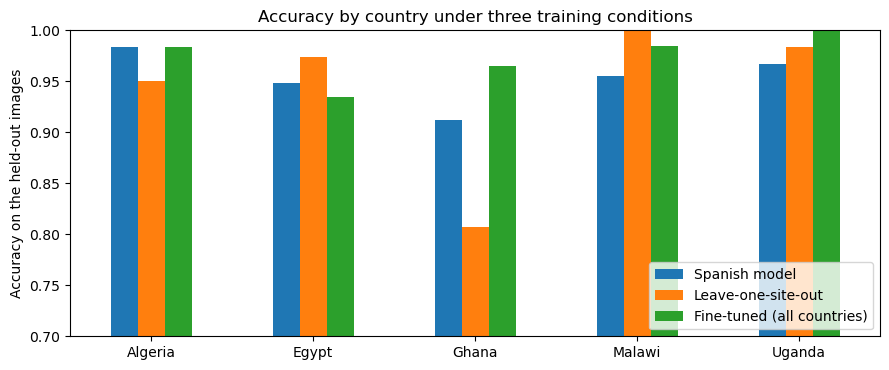

In [25]:
accuracy = site_results.xs("accuracy", axis=1, level=1).drop(index="All countries")

fig, ax = plt.subplots(figsize=(9, 3.8))
accuracy.plot.bar(ax=ax, rot=0)
ax.set_ylim(0.7, 1.0)
ax.set_ylabel("Accuracy on the held-out images")
ax.set_xlabel("")
ax.set_title("Accuracy by country under three training conditions")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES / "fig6_6_leave_one_site_out.png", dpi=300, bbox_inches="tight")
plt.show()

### 10.3 Errors on unseen sites

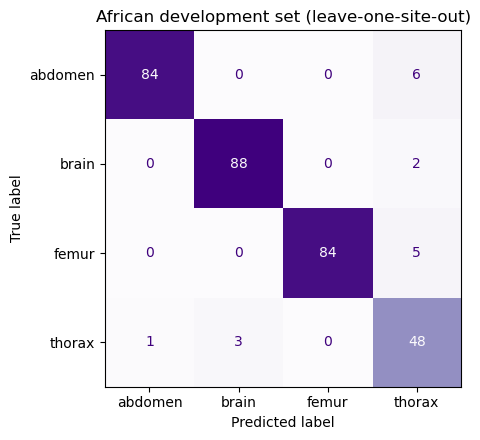

In [26]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(dev_labels, site_pred, labels=range(len(PLANES)),
                                        display_labels=SHORT_NAMES, cmap="Purples", ax=ax, colorbar=False)
ax.set_title("African development set (leave-one-site-out)")
plt.tight_layout()
plt.savefig(FIGURES / "fig6_7_confusion_matrix_leave_one_site_out.png", dpi=300, bbox_inches="tight")
plt.show()

### 10.4 Ghana on an unseen site

Ghana dropped the most when it was held out, so its misclassified images are shown here.

Ghana images misclassified: 11
Predicted as thorax: 11
Classified correctly by the Spanish model: 7


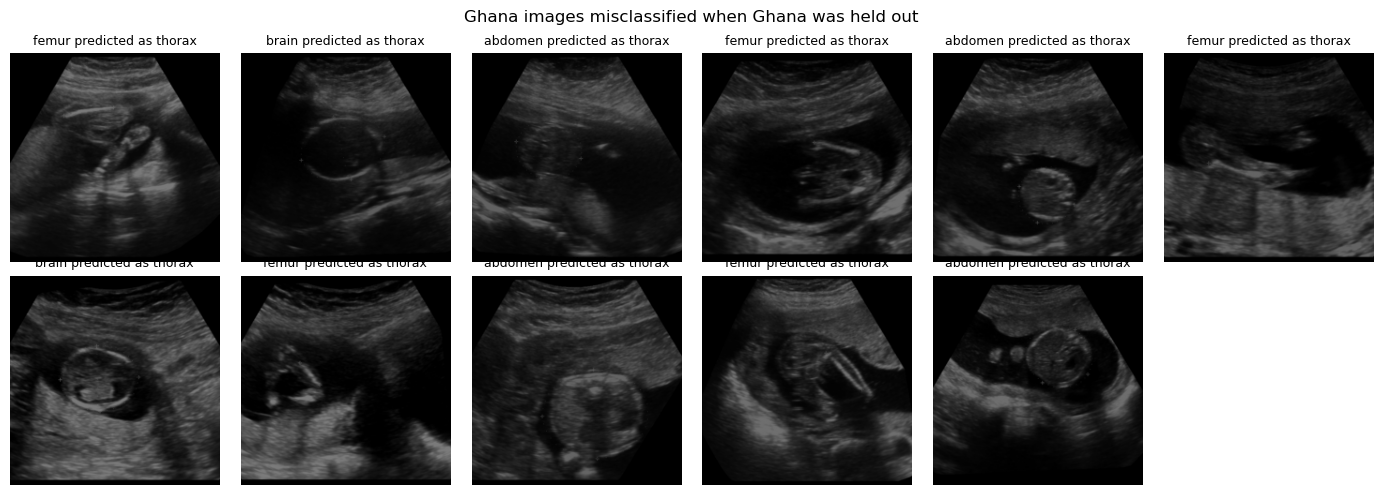

In [27]:
ghana_wrong = np.where((countries == "Ghana") & (site_pred != dev_labels))[0]
print("Ghana images misclassified:", len(ghana_wrong))
print("Predicted as thorax:", (site_pred[ghana_wrong] == PLANES.index("Fetal thorax")).sum())
print("Classified correctly by the Spanish model:", (pred_af[ghana_wrong] == dev_labels[ghana_wrong]).sum())

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), ghana_wrong):
    ax.imshow(dev_images[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{SHORT_NAMES[dev_labels[i]]} predicted as {SHORT_NAMES[site_pred[i]]}", fontsize=9)
fig.suptitle("Ghana images misclassified when Ghana was held out")
plt.tight_layout()
plt.show()

## 11. Leave-one-site-out summary

| Training condition | Seen this country? | Accuracy | Macro-F1 |
|---|---|---|---|
| Spanish model, no African training | No | 0.953 | 0.948 |
| Fine-tuned on the other four countries (leave-one-site-out) | No | 0.947 | 0.938 |
| Fine-tuned on all five countries (section 8) | Yes, other patients | 0.972 | 0.968 |

**Overall.** When a country was left out of training, fine-tuning on the other four African countries gave no gain on average: accuracy was 94.7%, against 95.3% for the Spanish model with no African training at all. The gains in section 8 therefore come mainly from having seen images from the same country, not from African data in general.

**By country.** The effect was mixed. Egypt, Malawi and Uganda improved (Malawi reached 100%), Algeria fell from 98.3% to 95.0%, and Ghana fell sharply from 91.2% to 80.7%.

**Ghana.** All 11 misclassified Ghana images were predicted as thorax, a plane that Ghana did not collect, and most of these were images the Spanish model had classified correctly (section 10.4). Ghana's images differ most from the other sites, as found in Phase 2, and the fine-tuned model treated this unfamiliar appearance as thorax. When Ghana images were included in training (section 8), the model learned that Ghana-looking images are never thorax. This is partly a site shortcut rather than better recognition of anatomy, so the Ghana result in section 8 should not be expected at a new hospital.

**Errors on unseen sites.** 13 of the 17 errors across all countries were predictions of thorax. On an unfamiliar site, thorax is the class the model falls back on.

**Caution.** Each country was held out once, with 57 to 77 images, so one image changes a country's accuracy by about 1.5 percentage points.

**What this means.** The section 8 results describe a model used at the hospitals it was trained on, which is also the situation of the African test set (same countries, new patients). The leave-one-site-out results describe a new hospital. For a new site, a small number of local images appears to help more than additional images from other African sites.

**Next step.** The final African model (section 8.4) will be scored once on the 75 African test images.


## 12. Test set evaluation

The 75 African test images (23 patients) were set aside in Phase 2 and have not been used for any training or decision so far. Here, the final African model from section 8.4 is scored on them **once**. Nothing is changed after this.

The test patients come from the same five countries as the development patients, so this result corresponds to section 8 (hospitals the model has seen), not to section 10 (a new hospital). The Spanish model is scored on the same images for comparison.

The test set is small: it has only 9 thorax images (none from Ghana or Uganda), and 12 to 18 images per country. To show how uncertain the scores are, I report a 95% confidence interval. It is calculated by resampling the 23 test patients with replacement 1,000 times and recalculating the scores each time.

In [28]:
test = african_clean[african_clean["partition"] == "test"]
test_images = african_images[test.index]
test_labels = test["label"].to_numpy()
test_loader = make_loader(test_images, test_labels)

final_model = load_model(MODELS / "african_finetuned.pt", device)
spanish_model = load_model(MODELS / "spanish_baseline.pt", device)

_, test_pred, _ = predict(final_model, test_loader, device)
_, test_pred_spanish, _ = predict(spanish_model, test_loader, device)
pd.crosstab(test["Center"], test["Plane"], margins=True)

Plane,Fetal abdomen,Fetal brain,Fetal femur,Fetal thorax,All
Center,,,,,
Algeria,4,4,4,4,16
Egypt,3,4,4,3,14
Ghana,6,6,6,0,18
Malawi,3,4,3,2,12
Uganda,5,5,5,0,15
All,21,23,22,9,75


### 12.1 Overall scores with confidence intervals

In [29]:
def patient_bootstrap(true, pred, patients, n=1000):
    rng = np.random.default_rng(random_seed)
    ids = np.unique(patients)
    scores = []
    for _ in range(n):
        rows = np.concatenate([np.where(patients == p)[0] for p in rng.choice(ids, len(ids))])
        scores.append([(pred[rows] == true[rows]).mean(),
                       f1_score(true[rows], pred[rows], average="macro", labels=np.unique(true[rows]))])
    return np.percentile(scores, [2.5, 97.5], axis=0)


rows = {}
for name, pred in [("Spanish model", test_pred_spanish), ("Final African model", test_pred)]:
    low, high = patient_bootstrap(test_labels, pred, test["patient_id"].to_numpy())
    rows[name] = {
        "correct": f"{(pred == test_labels).sum()} of {len(test_labels)}",
        "accuracy": round((pred == test_labels).mean(), 3),
        "accuracy 95% CI": f"{low[0]:.3f} to {high[0]:.3f}",
        "macro-F1": round(f1_score(test_labels, pred, average="macro"), 3),
        "macro-F1 95% CI": f"{low[1]:.3f} to {high[1]:.3f}",
    }
pd.DataFrame(rows).T

,correct,accuracy,accuracy 95% CI,macro-F1,macro-F1 95% CI
Spanish model,69 of 75,0.92,0.867 to 0.973,0.891,0.789 to 0.964
Final African model,73 of 75,0.973,0.933 to 1.000,0.969,0.925 to 1.000


### 12.2 Results by plane and country

In [30]:
report = classification_report(test_labels, test_pred, target_names=SHORT_NAMES, output_dict=True)
pd.DataFrame(report).T.round(3)

,precision,recall,f1-score,support
abdomen,1.000,0.952,0.976,21.000
brain,1.000,1.000,1.000,23.000
femur,0.955,0.955,0.955,22.000
thorax,0.900,1.000,0.947,9.000
accuracy,0.973,0.973,0.973,0.973
macro avg,0.964,0.977,0.969,75.000
weighted avg,0.975,0.973,0.974,75.000


In [31]:
test_results = test.assign(spanish_correct=(test_pred_spanish == test_labels), final_correct=(test_pred == test_labels))
test_columns = {"spanish_correct": "Spanish model", "final_correct": "Final African model"}
test_by_country = test_results.groupby("Center").agg(images=("final_correct", "size"),
                                                     **{v: (k, "mean") for k, v in test_columns.items()})
test_by_country.round(3)

,images,Spanish model,Final African model
Center,,,
Algeria,16,0.875,1.000
Egypt,14,0.929,0.929
Ghana,18,0.944,1.000
Malawi,12,0.917,1.000
Uganda,15,0.933,0.933


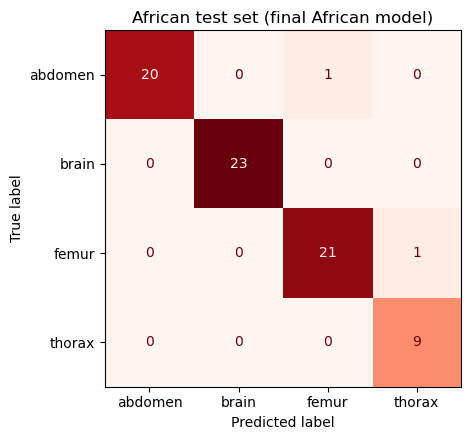

In [32]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(test_labels, test_pred, labels=range(len(PLANES)),
                                        display_labels=SHORT_NAMES, cmap="Reds", ax=ax, colorbar=False)
ax.set_title("African test set (final African model)")
plt.tight_layout()
plt.savefig(FIGURES / "fig6_8_confusion_matrix_test.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Test set summary

| | Correct | Accuracy (95% CI) | Macro-F1 (95% CI) |
|---|---|---|---|
| Spanish model, no African training | 69 of 75 | 0.920 (0.867 to 0.973) | 0.891 (0.789 to 0.964) |
| Final African model | 73 of 75 | 0.973 (0.933 to 1.000) | 0.969 (0.925 to 1.000) |

**Overall.** The final African model classified 73 of the 75 test images correctly (97.3%, macro-F1 0.969). This matches the cross-validation estimate from section 8 (97.2%), which suggests that the development results were not optimistic and that no information from the test set had influenced the model.

**Compared with the Spanish model.** Fine-tuning on African images improved the test score from 69 to 73 correct images. The confidence intervals overlap, so with 75 test images this difference is not conclusive on its own, but it agrees in direction with section 8.

**By plane.** All 23 brain and all 9 thorax images were correct. The two errors were one abdomen image predicted as femur and one femur image predicted as thorax. Thorax has only 9 test images, so its perfect recall is a weak result.

**By country.** Algeria, Ghana and Malawi were 100% correct, and Egypt and Uganda each had one error. Per-country scores are based on 12 to 18 images, so they are not compared further.

**What this result does and does not show.** The test patients come from the same five countries as the training patients, so 97.3% describes the model at hospitals it was trained on. Section 10 showed that at a new hospital, performance can be much lower (80.7% for Ghana when it was held out), mainly because unfamiliar images are predicted as thorax. Before the model is used at a new site, a small number of labelled images from that site should be collected to check and, if needed, fine-tune it.
